In [ ]:
from obspy import *
import obspy.signal
from obspy.signal.cross_correlation import correlation_detector
import pandas as pd
import matplotlib.pyplot as plt
from obspy.clients.fdsn import Client
import matplotlib.dates as mdates
import numpy as np
import datetime
import matplotlib.cm as cm
from obspy.signal.filter import envelope
import random
import matplotlib.ticker as ticker
from datetime import datetime

### DEFS

In [ ]:
def triggers_func(trig_times, peak_amps):
    trigger_df = pd.DataFrame(trig_times)
    trigger_df.rename(columns={trigger_df.columns[0]: 'onset'}, inplace=True)
   
    trigger_df['peak_amps m'] = peak_amps
    #trigger_df.set_index()
    trigger_df['onset'] = [t.datetime for t in trigger_df['onset']]
    #trigger_df[1] = [t.datetime for t in trigger_df[1]]
    trigger_df['month'] = trigger_df['onset'].dt.month
    trigger_df['day'] = trigger_df['onset'].dt.day
    trigger_df['hour_UTC'] = trigger_df['onset'].dt.hour
    #Times in local Antarctica time, better for daylight tracking, diurnal patterns
    trigger_df['local'] = trigger_df['onset'].dt.tz_localize('UTC').dt.tz_convert('Antarctica/McMurdo')
    trigger_df['hour_local'] = trigger_df['local'].dt.hour
    trigger_df['day_local'] = trigger_df['local'].dt.day
    
    #trigger_df.rename(columns={0:'onset'}, inplace = True)
    
    #Interevent spacing
    trigger_df['interevent_time'] = trigger_df['onset'].shift(-1) - trigger_df['onset']
    
    #Hourly and Daily counts
    trigger_df["hourly_counts"] = trigger_df.groupby(trigger_df['local'].dt.hour).size() #in local time
    hour_utc = trigger_df.groupby(trigger_df['onset'].dt.hour).size() #UTC
    daily_counts = trigger_df.groupby(trigger_df['local'].dt.day).size() #in local time
    daily_utc = trigger_df.groupby(trigger_df['onset'].dt.day).size()
    #trigger_df['amplitude m'] = pd.DataFrame(peak_amps) #amplitude - displacement in meters
    
    #Filtered to no events under 2 minute interspacing
    filtered_df = trigger_df[trigger_df['interevent_time'].dt.total_seconds() > 120]
    
    return trigger_df, filtered_df

## Template Matching ##

Read in templates. The templates were chosen by iterating over all sliced waveforms and using the cross correlators to get hits. The sliced waveforms with the  most hits were then written to mseed file.

In [ ]:
template1 = read('data/2025-11-22T01:45:58.275_template.mseed')
template2 = read('data/2025-11-22T10:50:39.225000Z_template.mseed')
template3 = read('data/2025-11-22T17:27:01.475000Z_template.mseed')
template4 = read('data/2025-11-22T13:27:46.925000Z_template.mseed')
templates = [template1,template2, template3, template4]
template_magnitudes = []
for t in templates:
    template_magnitudes.append(max(t[0]))

In [ ]:
templates
#for template in templates:
   # template.plot()
    #plt.show()

## Run the picker ##

In [ ]:
#%run vnda_picker_orig.py 2025-11-22T01:45:57.27 2025-11-22T01:46:25 --plot

#st.write('test_temp.mseed')

In [ ]:
%run vnda_picker_orig.py 2025-11-21T00:00:00 2025-11-21T03:00 


In [ ]:

#Make the DataFrame for the picker 
trigger_df, filtered_df = triggers_func(trig_times, peak_amps)
print('Trigger df', len(trigger_df), 'filtered df', len( filtered_df))
#Write these to csv
#trigger_df.to_csv(f"trigger_df_{trigger_df['onset'][0]}.csv")
#filtered_df.to_csv(f"filtered_df_{filtered_df['onset'][0]}.csv")

import os
output_dir = 'data'
file_name_trig = trigger_df['onset'].iloc[0].strftime('%Y-%m-%dT%H:%M:%s')
file_name_trig_filt = filtered_df['onset'].iloc[0].strftime('%Y-%m-%dT%H:%M:%s')
trigger_df.to_csv(os.path.join(output_dir, f"TRIGGER_{file_name_trig}.csv"))
filtered_df.to_csv(os.path.join(output_dir, f"TRIGGER_FILTERED_{file_name_trig_filt}.csv"))      

## Run cross correlator ##

Template files found: ['data/2025-11-22T10:50:39.225000Z_template.mseed', 'data/2025-11-22T13:27:46.925000Z_template.mseed', 'data/2025-11-22T17:27:01.475000Z_template.mseed', 'data/2025-11-22T01:45:58.275_template.mseed']
Start 2025-11-21T01:30:00.000000Z Stop 2025-11-21T03:30:00.000000Z Plot? False


/Users/kitsellusted/miniconda3/envs/pygmt-env/lib/python3.11/site-packages/obspy/clients/fdsn/client.py:251: ObsPyDeprecationWarning: IRIS is now EarthScope, please consider changing the FDSN client short URL to 'EARTHSCOPE'.
  warnings.warn(msg, ObsPyDeprecationWarning)
/Users/kitsellusted/grad_school/VANDA_work/vnda_picker_orig.py:52: ObsPyDeprecationWarning: attach_response is deprecated and will be removed in a future release. Use remove_response() instead.
  st = client2.get_waveforms(


TEMPLATE 0 2025-11-22T10:50:39.225000Z
NUMBER of DETECTIONS 9
TEMPLATE 1 2025-11-22T13:27:46.925000Z
NUMBER of DETECTIONS 0
TEMPLATE 2 2025-11-22T17:27:01.475000Z
NUMBER of DETECTIONS 6
TEMPLATE 3 2025-11-22T01:45:58.275000Z
NUMBER of DETECTIONS 15
Making dataframe with correlations
Making dataframe with filtered correlations
template 2 has no entries in its detections.
Making dataframe with correlations
Making dataframe with filtered correlations
Making dataframe with correlations
Making dataframe with filtered correlations


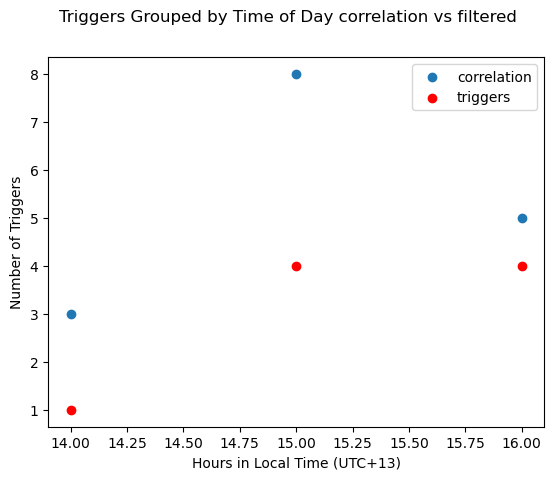

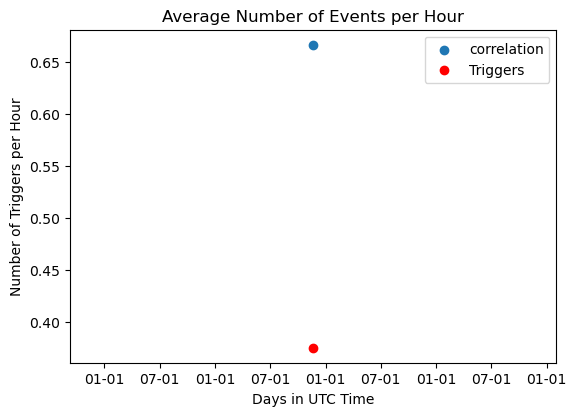

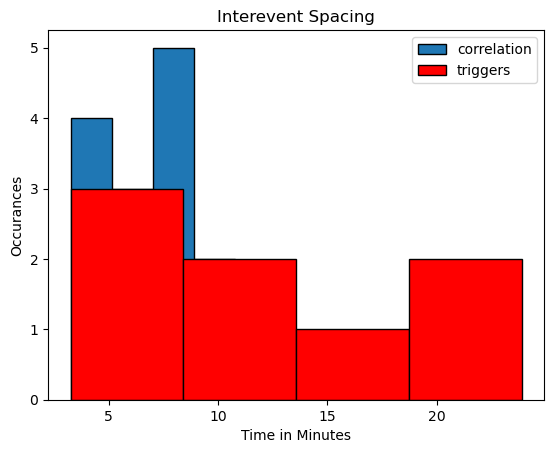

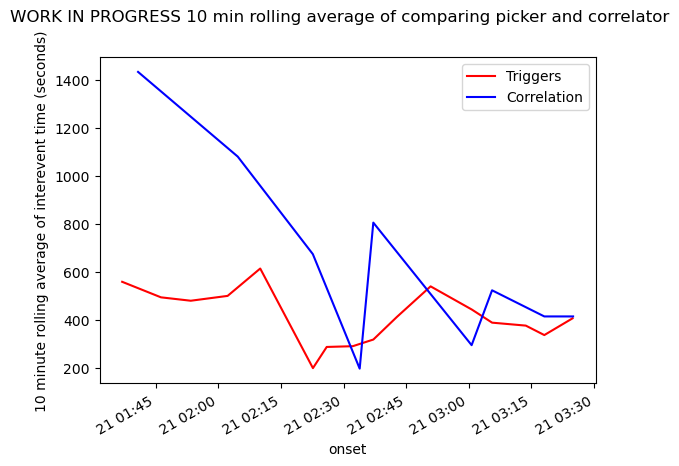

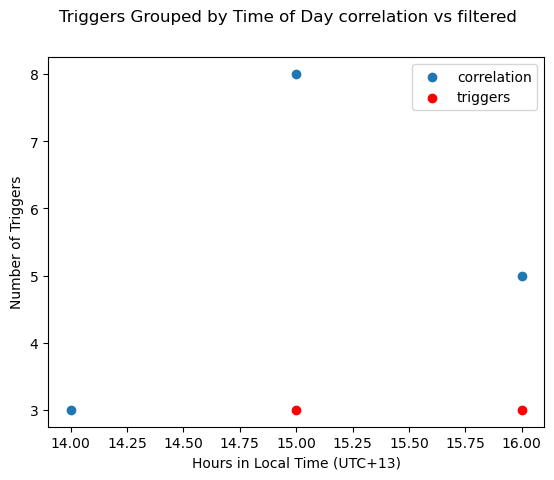

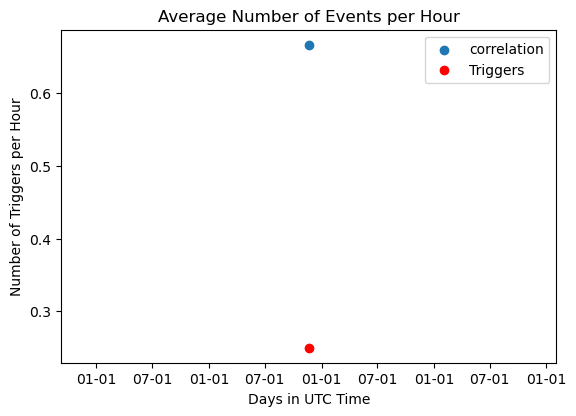

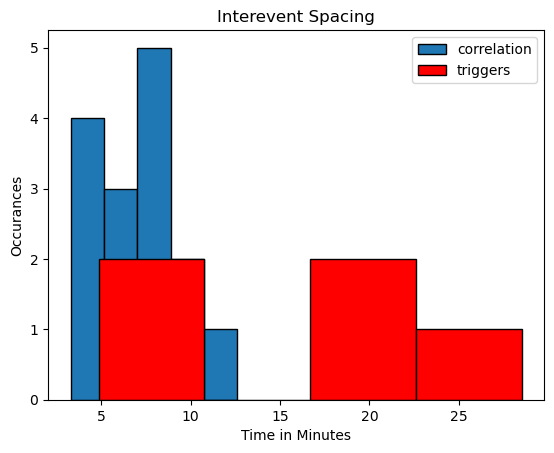

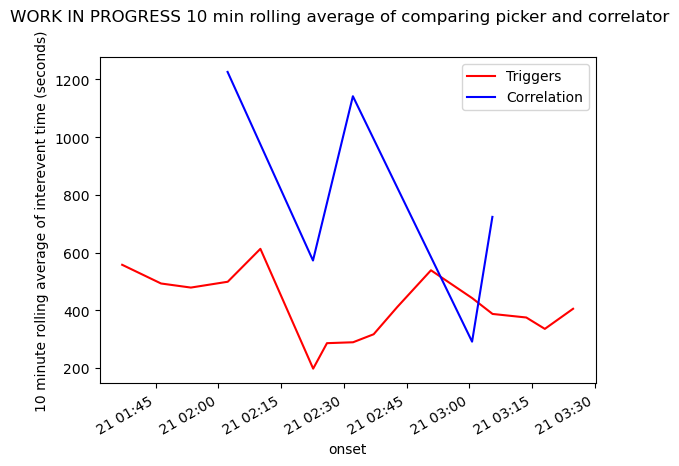

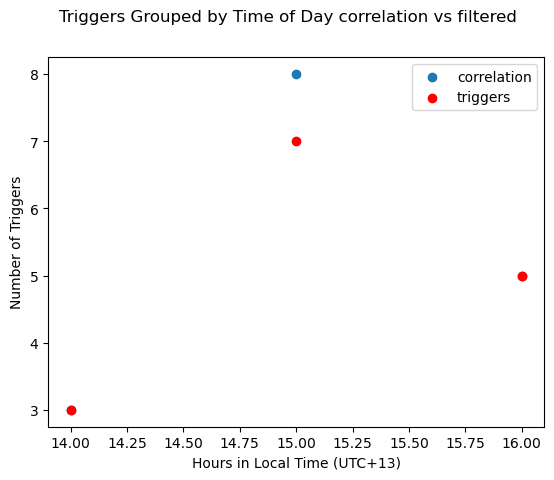

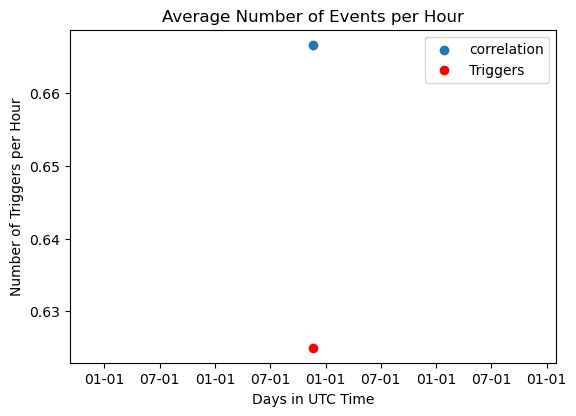

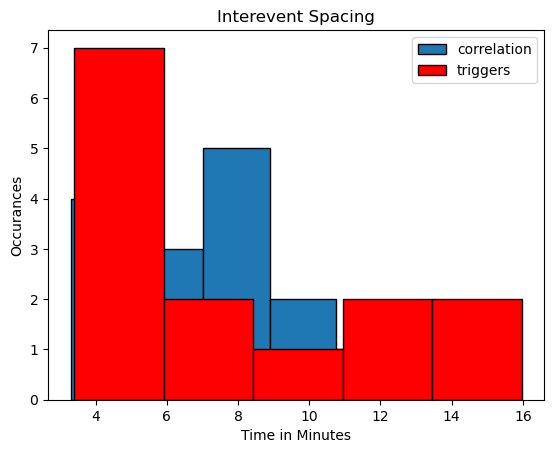

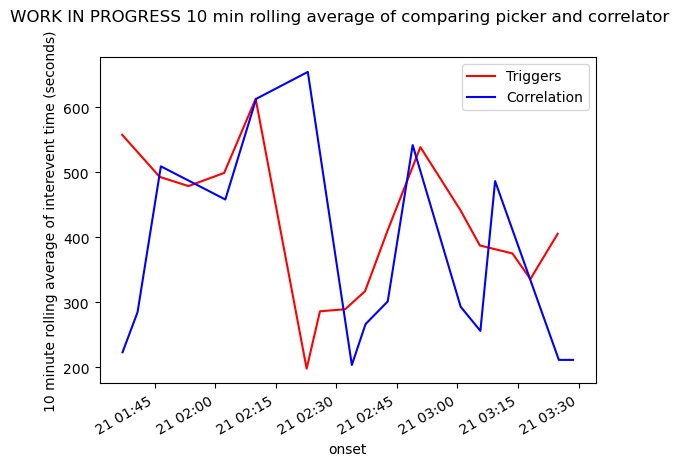

In [29]:
import sys
from glob import glob
from obspy import *


# 1. Temporarily set sys.argv to only the two dates so we can safely import vnda_picker_orig
date1 = '2025-11-21T01:30'
date2 = '2025-11-21T03:30'
#plot = "--plot"
sys.argv = ['vnda_picker_orig.py', date1, date2]

from vnda_picker_orig import picker

# 2. Collect the template files
template_list = glob('data/*.mseed')
print("Template files found:", template_list)

# 3. Now programmatically set sys.argv with templates and dates for correlation_function.py
args_string = " ".join(template_list) + " "+ date1+" "+date2

# 4. Run the script
%run correlation_function.py $args_string



In [28]:
type(file_corr[0])

pandas.core.frame.DataFrame

In [22]:
#Plot results
corr_name_list = glob('data/CORR_*')
trigger_name_list = glob('data/Trig_filt*')
corr_name_list
for i, c in enumerate(corr_name_list):
    print(c, trigger_name_list)
    %run hist_outline.py c trigger_name_list

data/CORR_2025-11-21T01:40:46.csv ['data/Trig_filt_2025-11-21 01:46:16.200000.csv']


NameError: name 'correlation' is not defined

data/CORR_2025-11-21T02:02:11.csv ['data/Trig_filt_2025-11-21 01:46:16.200000.csv']


NameError: name 'correlation' is not defined

data/CORR_2025-11-21T01:37:03.csv ['data/Trig_filt_2025-11-21 01:46:16.200000.csv']


NameError: name 'correlation' is not defined

In [20]:
for i, c in corr_name_list:
    print(c, trigger_name_list)

ValueError: too many values to unpack (expected 2)

In [ ]:
#TEMPLATE 1
for template in template_list:
    
    %run hist_outline.py 'data/CORR_2025-11-21T00:01:1763715692.csv' 'data/TRIGGER_FILTERED_2025-11-21T00:01:1763715695.csv'

In [ ]:
#This could be a function
print('LENGTH of SLICED_WVF', len(sliced_wvf))

detection_time= []
corrs = []
mags = []
more_ds = []

for i, template in enumerate(templates):
    #template = test_temp
    
    #height = [0.4,0.8,0.1]
    height = [0.4]
    ds = []
    d = []
    c = []
    m = []
    for h in height:
        distance = len(templates[i][0])
        
        detections, corr = correlation_detector(st, template, h, distance, template_magnitudes=template_magnitudes, template_names = i)
        more_ds.append(detections)
        for det in detections:
        
            d.append(det['time'])
            c.append(det['similarity'])
            m.append(det['magnitude'])
        print(f'TEMPLATE {template[0].stats.starttime}')
        print(f'NUMBER of DETECTIONS {len(detections)}') 
        #print(f'AMPS {mean(detections)}') 
    #more_ds.append(ds)
    detection_time.append(d)
    corrs.append(c)
    mags.append(m)
#ds_corrs = pd.DataFrame([more_ds])

In [ ]:
for i, d in enumerate(more_ds):
    print(len(d))

In [ ]:
import os
output_dir = 'data'
for i, d in enumerate(more_ds):
    if len(d)>0:
        CORR_df, FILTERED_corr = triggers_func(d, mags[i])
        file_name_corr = CORR_df['onset'].iloc[0].strftime('%Y-%m-%dT%H:%M:%s')
        file_name_filt = FILTERED_corr['onset'][0].strftime('%Y-%m-%dT%H:%M:%s')
        CORR_df.to_csv(os.path.join(output_dir, f"CORR_{file_name_corr}.csv"))
        FILTERED_corr.to_csv(os.path.join(output_dir, f"FILT_{file_name_filt}.csv"))
    else:
        print(f'template {i+1} has no entries in its detections.')


In [ ]:
#TEMPLATE 1
for template in template_list:
    
    %run hist_outline.py 'data/CORR_2025-11-21T00:01:1763715692.csv' 'data/TRIGGER_FILTERED_2025-11-21T00:01:1763715695.csv'

In [ ]:
clean_a

In [ ]:
dfs = [trigger_df, CORR_df]
fig, ax = plt.subplots(figsize=(10, 8))
for d,df in enumerate(dfs):
    name = ['correlation', 'triggers']
    month_dict = {i: calendar.month_name[i] for i in range(1, 13)}
    num_months = int(df['month'].nunique())
    color = sns.color_palette()
    #filt_min = filtered_df['interevent_time'].dt.total_seconds()/60
    print(f'there are {num_months} months')
    
    #bins = 80
    for i , month in enumerate(df['month'].unique(), start = 0):
            #month = trigger_df[trigger_df.index.month == month]
            #interevent_spacing = trigger_df['interevent_time'].dt.total_seconds()/60
            #print(month)
        data = df[df['onset'].dt.month == month][['interevent_time']]
        data.dropna()
            
        a = data['interevent_time'].dt.total_seconds()/60
        clean_a = a[np.isfinite(a)]
        filt_min = round(data.mean(),2)
        #color = sns.color_palette()
        
        #print(data), print(type(data))
        #monthly_triggers = trigger_df.groupby(trigger_df['onset'].dt.to_period('M'))['interevent_time']
        bins = np.histogram_bin_edges(a=clean_a, bins='auto')
        #print(bins)
        #ax.scatter(pd.to_datetime(df['onset']).dt.date.unique(), daily_utc)
        #ax.hist(a, bins = bins, edgecolor = 'black', label = f'trigger counts for month {month}', color = color[d])
        #ax.axvline(x = filt_min.iloc[0].total_seconds()/60, color = 'black', linestyle = '--', linewidth = 2, label = f'{round(filt_min.iloc[0].total_seconds()/60,2)} minutes')
        sns.kdeplot(clean_a,color = color[d], fill = True, label = f'{name[d]} {month_dict[month]} average {round(filt_min.iloc[0].total_seconds()/60,2)} minutes')
ax.legend()

ax.set_xlim(-1)
#ax.set_xticklabels([])
#ax.set_xticks([])
ax.set_xlabel("Time (min)")

#fig.supxlabel('Time in Minutes')

fig.tight_layout()
fig.suptitle(" Histogram for Intervent Trigger Spacing", ha='center', va='top')
fig.subplots_adjust(top=0.88)
#fig.supylabel('Occurances')
#fig.suplegend()
plt.show()

In [ ]:
import glob
file_pattern = "data/*CORR*.csv"
trigger_pattern = "data/*TRIGGER_FILTERED*.csv"
all_corrs = glob.glob(file_pattern)
trigs = glob.glob(trigger_pattern)

#%run hist_outline.py $file_pattern
for f, file in enumerate(all_corrs):
    for t in trigs:
        print(f'comparison of template number {f} to filtered trigger')
        %run hist_outline.py $file $t
    
#df_list = [pd.read_csv(file) for file in all_files]
#combined_df = pd.concat(df_list, ignore_index=True)
#combined_df
#%run hist_outline.py 'trigger_df_2025-11-21 00:01:35.325000.csv'

In [ ]:
df1_rolling.max()

len(df1_rolling), len(df_rolling)

In [ ]:
df = trigger_df
df1 = CORR_df

df_rolling = df[['onset', 'interevent_time']].set_index('onset')
df_rolling['interevent_time'] = df_rolling['interevent_time'].dt.total_seconds()

df1_rolling = df1[['onset', 'interevent_time']].set_index('onset')
df1_rolling['interevent_time'] = df1_rolling['interevent_time'].dt.total_seconds()

rolling_avg_df = df_rolling.rolling('600s').mean()
rolling_avg_df1 = df1_rolling.rolling('600s').mean()

fig, ax = plt.subplots()

rolling_avg_df.plot(ax=ax, color = 'red')
rolling_avg_df1.plot(ax=ax, color = 'blue')

ax.legend(['Triggers', 'Correlation'])
ax.set_ylabel('10 minute rolling average counts')
fig.suptitle('10 min rolling average of comparing picker and correlator')
plt.show()

In [ ]:
df = filtered_df
df1 = CORR_df
df_rolling = df[['onset', 'interevent_time']]
df_rolling.rolling('10m').sum()

fig, ax = plt.subplots()

ax.scatter(df['onset'], df['Unnamed: 0'], label = 'triggers')

ax.set_xlabel('Days in UTC Time')
ax.set_title("Number of Events per Hour")
ax.set_ylabel('Triggers')
#ax.set_ylim(0, 25)
fig.tight_layout(pad=3.0) 
fig.legend()
fig.add_gridspec(8, 8, wspace=0, hspace=0)



In [ ]:
more_ds[0]

### DEFS for PLOTTING ##

In [ ]:
### DEFS for plotting
def graphs(df):
    
    #df1['interevent_time'] = abs(df1['time'].shift(-1) - df1['time'])
    #df = df1[df1['interevent_time'].dt.total_seconds() > 120]
    df['month'] = df['time'].dt.month
    df['day'] = df['time'].dt.day
    df['hour_UTC'] = df['time'].dt.hour
    
    #Times in local Antarctica time, better for daylight tracking, diurnal patterns
    df['local'] = df['time'].dt.tz_localize('UTC').dt.tz_convert('Antarctica/McMurdo')
    df['hour_local'] = df['local'].dt.hour
    df['day_local'] = df['local'].dt.day
    
    #Calculate hourly/daily metrics
    hourly_counts = df.groupby(df['time'].dt.hour).size() #in local time
    hour_utc = df.groupby(df['time'].dt.hour).size() #UTC
    daily_counts = df.groupby(df['time'].dt.date).size() #in local time
    daily_utc = df.groupby(df['time'].dt.date).size()
    
    df["hourly_counts"] = df.groupby(df['local'].dt.hour).size() #in local time
    hour_utc = df.groupby(df['time'].dt.hour).size() #UTC
    daily_counts = df.groupby(df['local'].dt.day).size() #in local time
    daily_utc = df.groupby(df['time'].dt.day).size()
    
    #Average values
    filt_min = df['interevent_time'].dt.total_seconds()/60
    daily_mean = (daily_utc/24).mean()
    
    
    #Plot hourly variation of signal detection
    fig, ax = plt.subplots()
    ax.scatter(df['hour_local'].unique(), hourly_counts) #local time
    ax.set_xlabel('Hours in Local Time (UTC+13)')
    ax.set_ylabel('Number of Triggers')
    ax.set_ylim(None,None)
    #ax.scatter(df1['hour_local'].unique(), df1.groupby(df1['local'].dt.hour).size(), color = 'red', label = 'Filtered for double count') #local time
    ax.legend()
    fig.suptitle('Correlations Grouped by Time of Day ')
    
    #Plot Average Number of Events per Hour
    fig, ax = plt.subplots()
    #ax.scatter(pd.to_datetime(df['onset']).dt.date.unique(), daily_utc)
    ax.scatter(pd.to_datetime(df['time']).dt.date.unique(), daily_utc/(24), label = 'trigger counts', color = 'purple', edgecolor = 'black') #pick per hour
    
    ax.axhline(y = round(daily_mean,2), color = 'black', linestyle = '--', linewidth = 2, label = f'{round(daily_mean,2)}, triggers', alpha = 0.7)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
    ax.set_xlabel('Days in UTC Time')
    #ax.set_ylim(5,12)
    ax.set_title("Average Number of Events per Hour")
    ax.set_ylabel('Triggers per Hour')
    ax.legend()
    #plt.savefig(f"Number_events_{filtered_df['local'].dt.date.min()}_to_{filtered_df['local'].dt.date.max()}",dpi=200)

    fig, ax = plt.subplots()
    #ax.scatter(pd.to_datetime(df['onset']).dt.date.unique(), daily_utc)
    ax.hist(df['interevent_time'].dt.total_seconds()/60, bins = 80, edgecolor = 'black', label = 'correlation counts')
    ax.axvline(x = round(filt_min.mean(),2), color = 'black', linestyle = '--', linewidth = 2, label = f'{round(filt_min.mean(),2)} minutes', alpha = 0.7)
    ax.set_xlabel('Time in Minutes')
    ax.set_title("Interevent Spacing")
    ax.set_ylabel('Occurances')
    ax.legend()
    #plt.show()
    #plt.savefig(f"Intervent_Time_{filtered_df['local'].dt.date.min()}_to_{filtered_df['local'].dt.date.max()}",dpi=200)
    

    fig, ax = plt.subplots()

    #ax = df.groupby(pd.Grouper(key='onset', freq='h')).size().plot(color = 'blue')
    hourly_counts = df.groupby(pd.Grouper(key='time', freq='h')).size()
    ax = hourly_counts.plot(color = 'red', label = 'trigger counts')
    ax.set_xlabel('Days in UTC Time')
    ax.set_title("Number of Events per Hour")
    ax.set_ylabel('Triggers')
    ax.set_ylim(0, 25)
    fig.tight_layout(pad=3.0) 
    fig.legend()
    fig.add_gridspec(8, 8, wspace=0, hspace=0)
    return None

In [ ]:
%run hist_outline.py 'correlation_df_2003-11-21 00:10:23.700000.csv'

In [ ]:
df_filt
graphs(df_filt)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['red', 'blue','green', 'orange', 'purple']

for i, detect_list in enumerate(detection_time):
    print(i)
    times = pd.to_datetime([t.datetime for t in detection_time[i]])
    for a,time in enumerate(times):
        #print(again)
        symbols = ['o', 's', 'D', 'v']
        plt.plot(time, corrs[i][a], symbols[i], color = colors[i], label = f'template {i+1}', alpha = 0.6)
        fig.autofmt_xdate(rotation=45)
            
    tfmt = mdates.DateFormatter('%Y-%m-%d %H:%M')
    ax.xaxis.set_major_formatter(tfmt)

ax.set_xlabel('%s [UTC]' % st[0].stats.starttime.strftime('%Y-%m-%d'))
ax.set_ylim(0,1.1)
handles, labels = ax.get_legend_handles_labels()

# 2. Filter duplicates using a dictionary (keeps the first occurrence)
by_label = dict(zip(labels, handles))

# 3. Pass the unique groups to the legend
ax.legend(by_label.values(), by_label.keys())
#ax.legend()
plt.show()

In [ ]:
%run vnda_picker_orig.py 2003-11-21T00:00:00 2003-11-29T00:00

print(len(sliced_wvf))


In [ ]:
df_filt['interevent_time'].mean()

In [ ]:
print('LENGTH of SLICED_WVF', len(sliced_wvf))

detection_time= []
corrs = []
more_ds = []
for i, template in enumerate(templates):
    #height = [0.4,0.8,0.1]
    height = [0.4]
    ds = []
    d = []
    c = []
    for h in height:
        distance = len(templates[i][0])
        
        detections, corr = correlation_detector(st, template, h, distance, template_names = i)
        more_ds.append(detections)
        for det in detections:
            
            d.append(det['time'])
            c.append(det['similarity'])
        
        print(f'TEMPLATE {template[0].stats.starttime}')
        print(f'NUMBER of DETECTIONS {len(detections)}') 
    
    #more_ds.append(ds)
    detection_time.append(d)
    corrs.append(c)
#ds_corrs = pd.DataFrame([more_ds])
ds_corrs=pd.DataFrame(more_ds[0]) # just using template #1
#for d in more_ds:
    #ds_corrs = pd.concat([ds_corrs, pd.DataFrame(d)])
ds_corrs= ds_corrs.drop(columns='template_id')# now there is a dataframe that we can replicate the results of the picker
ds_corrs['time'] = pd.to_datetime([t.datetime for t in ds_corrs['time']])
ds_corrs['interevent_time'] = abs(ds_corrs['time'].shift(-1) - ds_corrs['time'])
df_filt = ds_corrs[ds_corrs['interevent_time'].dt.total_seconds() > 120]

print(len(ds_corrs), len(df_filt))
df_filt
graphs(df_filt)

In [ ]:
ds = []
detection_time= []
corrs = []

for i, template in enumerate(templates):
    #height = [0.4,0.8,0.1]
    height = [0.4]
    
    d = []
    c = []
    for h in height:
        distance = len(templates[i][0])
        detections, corr = correlation_detector(st, template, h, distance)
        for det in detections:
            
            d.append(det['time'])
            c.append(det['similarity'])
        
        print(f'TEMPLATE {template[0].stats.starttime}')
        print(f'NUMBER of DETECTIONS {len(detections)}')  
    detection_time.append(d)
    corrs.append(c)

fig, ax = plt.subplots(figsize=(10, 6))
colors = ['red', 'blue','green', 'orange', 'purple']

for i, detect_list in enumerate(detection_time):
    print(i)
    times = pd.to_datetime([t.datetime for t in detection_time[i]])
    for a,time in enumerate(times):
        #print(again)
        symbols = ['o', 's', 'D', 'v']
        plt.plot(time, corrs[i][a], symbols[i], color = colors[i], label = f'template {i+1}', alpha = 0.6)
        fig.autofmt_xdate(rotation=45)
            
    tfmt = mdates.DateFormatter('%Y-%m-%d %H:%M')
    ax.xaxis.set_major_formatter(tfmt)

ax.set_xlabel('%s [UTC]' % st[0].stats.starttime.strftime('%Y-%m-%d'))
ax.set_ylim(0,1.1)
handles, labels = ax.get_legend_handles_labels()

# 2. Filter duplicates using a dictionary (keeps the first occurrence)
by_label = dict(zip(labels, handles))

# 3. Pass the unique groups to the legend
ax.legend(by_label.values(), by_label.keys())
#ax.legend()
plt.show()

In [ ]:
sys.exit()

In [ ]:
keepers = [] #index of sliced waveform
detection_time= []
corrs = []
ds = []

height = 0.4
print(f'There are {len(sliced_wvf)} slices in this period.')
print('Trying slices')
print('  ')
for i, sl in enumerate(sliced_wvf):
    
    distance = len(sl)  # distance between detections in seconds, probably adjust
    #print(len(sl))
    #print(distance)
    detections, corr = correlation_detector(st, Stream(sl), height, distance)
    
    print(f'sl #{i} triggered {len(detections)} times!')
    #sl.plot()
    if len(detections)>=1:
        times = []
        #print(f'sl #{i} triggered {len(detections)} times!')
        keepers.append(sliced_wvf[i])
        for a, d in enumerate(detections):
            
            if np.around(d['similarity'],4) == 1:
                
                print(f"SELF TRIGGER {d['similarity']}")
                print(' ')
                pass
            
            else: 
                
                ds.append(len(detections))
                times.append(d)
                
                #corrs.append(corrs)
                #print(f'Detection for sl #{i}, detection #{a+1}')
                #print(f'sl starting at {sl.stats.starttime}')
                #print(f"DETECTION TIME | {UTCDateTime(d['time'])} CORR | {round(d['similarity'],2)}")
                #print(f'QC TEST: {sl.stats.starttime - d["time"]}')
                #print(' ')
                #correlation_detector(st, Stream(sl), height, distance, plot = st)
                #sl.plot()
                
                #detection_time.append(d['time'])
                #corrs.append(d['similarity'])
                #print(len(times))
        detection_time.append(times)
    
        #print(f'No matches for sl # {i}')
        #detections, corr = correlation_detector(st, Stream(sl), height, distance, plot = st)
        #print('  ')

print(f'There were a total of {len(detection_time)} detections in this time period')

In [ ]:
sys.exit()

In [ ]:
fig, ax = plt.subplots()
for i, k in enumerate(keepers):
    
    ax.plot(k.stats.starttime.matplotlib_date, ds[i], 'o')
    tfmt = mdates.DateFormatter('%H:%M:%S')
#ax.set_ylabel('Normalized Displacement m')
ax.set_xlabel('%s [UTC]' % keepers[0].stats.starttime.strftime('%Y-%m-%d'))
#ax.legend()

    fig.autofmt_xdate(rotation=45)
    ax.xaxis.set_major_formatter(tfmt)
    ax.xaxis_date()
    # Turn on a grids
    ax.grid(True, 'both')     
    # Title
plt.show()

In [ ]:
vnda_big = read('vnda_wiggle_big_one.mseed')
vnda_big.taper(0.01)
vnda_big.trim(UTCDateTime('2025-11-25T02:09:23'), UTCDateTime('2025-11-25T02:09:35'))
#vnda_big.trim(vnda_big[0].stats.starttime-70, vnda_big[0].stats.endtime)
vnda_big.plot()
plt.show()


In [ ]:
#%run vnda_picker_orig.py 2025-11-21T00:00:00 2025-11-21T05:00:00
print(f'length of sliced waveforms {len(sliced_wvf)}')
#st.taper(0.01)
height = .3  # similarity threshold, Probably adjust
distance = 10
print('Mr. Big')
detections, corr = correlation_detector(st, vnda_big, height, distance, plot = st)
print(f'NUMBER of DETECTIONS {len(detections)}')
#Check if Mr Big is triggering on Mr Big
corrs = []
#Print all the times Mr. Big gets detected
for d in detections:
    
    if vnda_big[0].stats.starttime == d['time']:
        print('This is Mr. Big triggering on Mr. Big')
        print(f"TIME | {UTCDateTime(d['time'])} CORR | {round(d['similarity'],2)}")
        
    else:
        corrs.append(d['similarity'])
        #print('It triggered!')
        #print(f"TIME | {UTCDateTime(d['time'])} CORR | {round(d['similarity'],2)}")
plt.hist(corrs, bins = 20)

In [ ]:
sl = read('2025-11-21T00:01:30.325000Z.mseed')
sl.trim(UTCDateTime('2025-11-21T00:01:33'), UTCDateTime('2025-11-21T00:01:40'))
sl.taper(0.01)
sl.plot()
corrs = []
detections, corr = correlation_detector(st, Stream(sl), 0.2, 10)
print(len(detections))
for d in detections:
    if sl[0].stats.starttime != d['time']:
    
        corrs.append(d['similarity'])
plt.hist(corrs, bins = 20)
plt.show()

In [ ]:
%run vnda_picker_orig.py 2025-11-21T02:00:00 2025-11-21T04:00:00 --plot

In [ ]:
keepers

In [ ]:

fig, ax = plt.subplots(len(keepers)+1, figsize = (len(keepers)+2,len(keepers)+4))
colors = cm.viridis(np.linspace(0, 1, len(keepers)))

for i, trigger in enumerate(detection_time):
    for num, a in enumerate(trigger):  
        if num ==0:
            ax[i].scatter(a['time'].datetime, a['similarity'], marker = 's', facecolor = colors[i], alpha = 1, edgecolors='black', s=80, label = f'{a["time"].datetime}')
            ax[i].axvline(x=keepers[i].stats.starttime, color=colors[i], linestyle='--', linewidth=2)
            #ax[i].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d %H:%M:%S UTC"))
        else:
            ax[i].scatter(a['time'].datetime, a['similarity'], marker = 's', facecolor = colors[i], alpha = 1, edgecolors='black', s=80)
            #ax[i].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d %H:%M:%S UTC"))
            #ax.set_xticks(a['time'].datetime)
    #ax.axhline(y = a['similarity']+i*2, color = 'black')
    

    #ax[i].set_xlim(sliced_wvf[0].stats.starttime-50, sliced_wvf[-1].stats.endtime+50)
   # ax[i].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d %H:%M:%S UTC"))
    #ax[i].set_ylabel('Correlation')
    #ax[i].set_xlabel('Date')
    ax[i].set_ylim(0,1.2)
    
    
    ax[i].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d %H:%M:%S UTC"))

#ax[i].set_title('Correlation vs Time detected')
fig.legend(loc = 'right')
#fig.tight_layout()
plt.show()


In [ ]:
fig, ax = plt.subplots()
ax.bar(keepers[i].times("matplotlib"), len(detection_time[i]))
fig.autofmt_xdate(rotation=45)
fig.autofmt_xdate()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d %H:%M:%S UTC"))

In [ ]:
print(len(keepers))

for i, k in enumerate(keepers):
    
    print(i, k)
ds


In [ ]:
#trig_datetimes = [t.datetime for t in keepers]
fig, ax = plt.subplots()
for i, k in enumerate(keepers):
    ax.scatter(k.stats.starttime, corrs[i], marker = 'o', edgecolors='black', s=50, label = f'{k}')
    
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d %H:%M:%S UTC"))
    #fig.autofmt_xdate()
    ax.set_ylabel('Correlation')
    ax.set_xlabel('Date')
    ax.set_ylim(0.5,1)
    ax.set_xticks(py_datetimes)
fig.legend()
ax.set_title('Correlation vs Time of template used')
plt.show()

In [ ]:
fig, ax = plt.subplots(len(keepers),2)

for i, k in enumerate(keepers):
    trm = st.copy()
    trm.trim(detection_time[i], detection_time[i] + (k.stats.endtime - k.stats.starttime))
    ax[i,0].plot(trm[0].times(), trm[0].data +max(k.data), color = 'red', alpha = 0.7, label = 'trigger in stream')
    ax[i,0].plot(k.times(), k.data, color = 'black', alpha = 0.8, label = f'template: corr {round(corrs[i],2)}')
    #ax[0,1].scatter(i, corrs[i], label = detection_time[i])
    
    fig.supxlabel('%s [UTC]' % trm[0].stats.starttime.strftime('%Y-%m-%d'))
    fig.legend(loc=(0.7, 0.5))
    #tfmt = mdates.DateFormatter('%H:%M:%S')
    f
    #ax[-1,0].xaxis.set_major_formatter(tfmt)
    #ax[-1,0].xaxis_date()
    ax[-1,0].grid(True, 'both')  

    

In [ ]:
%run vnda_picker_orig.py 2025-11-25T00:00:00 2025-11-25T01:00:00
print(len(sliced_wvf))
sliced_wvf[0].plot()
wiggle = Stream(sliced_wvf[0].trim(sliced_wvf[0].stats.endtime-10))
wiggle.plot()
print("onsettime", ' / ', "Index in sliced_wvf", " / ", "Number of Hits with this Wiggle")
st.taper(0.01)
st.plot()
height = 0.5  # similarity threshold, Probably adjust
distance = 0.5  # distance between detections in seconds, probably adjust

long = Stream(sliced_wvf[0])
wiggle.plot()
long.plot()
correlation_detector(Stream(long), Stream(wiggle), height, distance, plot = Stream(long))


In [ ]:
%run vnda_picker_orig.py 2025-11-25T00:00:00 2025-11-25T10:00:00
print(len(sliced_wvf))
hr = st.slice(st[0].stats.starttime+0.1*3600, st[0].stats.endtime)
print("onsettime", ' / ', "Index in sliced_wvf", " / ", "Number of Hits with this Wiggle")
hr.plot()

#Let's correlate each sliced waveform with the other waveforms
smaller_wiggles = []
big_wiggles = []
wiggle_names = []
for wiggle in sliced_wvf:
    wiggle = Stream(wiggle)
    height = 0.5  # similarity threshold, Probably adjust
    distance = 1  # distance between detections in seconds, probably adjust
    detections, sims = correlation_detector(, wiggle, height, distance)
        
    if 4<len(detections)<=6:
        print("hr:",  st[0].stats.starttime, "to", st[0].stats.starttime+3600)
        print(wiggle[0].stats.starttime, sliced_wvf.index(wiggle[0]),len(detections))
        big_wiggles.append(Stream(wiggle[0]))
        wiggle.plot()
        correlation_detector(Stream(hr), wiggle, height, distance, plot = hr)
        wiggle_names.append(f'wiggle_{sliced_wvf.index(wiggle[0])}')
        # writing the template wiggle to file so I can read it in later
        wiggle.write(f'bigger_template_wiggle_{sliced_wvf.index(wiggle[0])}.mseed', format = "MSEED") 
    if len(detections)>30:
        print("hr:",  st[0].stats.starttime, "to", st[0].stats.starttime+3600)
        print(wiggle[0].stats.starttime, sliced_wvf.index(wiggle[0]),len(detections))
        smaller_wiggles.append(Stream(wiggle[0]))
        wiggle.plot()
        correlation_detector(Stream(hr), wiggle, height, distance, plot = hr)
        wiggle_names.append(f'wiggle_{sliced_wvf.index(wiggle[0])}')
        # writing the template wiggle to file so I can read it in later
        wiggle.write(f'smaller_template_wiggle_{sliced_wvf.index(wiggle[0])}.mseed', format = "MSEED") 
    #template.plot()
#Looks like wiggle #14 is a good template, but let's use anything over 5 hits on 3 hours
#How can I save wiggle #14 so that even if I have a different starting point it will still work? write wiggle as a mseed?

In [ ]:

fig,ax = plt.subplots(2, figsize=(10,5))
fig.suptitle('VNDA Signals Overlaid')
fig.supxlabel('Time (s)')
fig.supylabel('Displacement (m)')
time = big_wiggles[0]

for i, trace in enumerate(big_wiggles):
    cmap = plt.colormaps['gist_heat']
    print(i)
    #trace.normalize()
    color_list = [cmap(i) for i in np.linspace(0, 1, len(big_wiggles))]
    ax[0].plot(trace[0].times(), trace[0].data, color=color_list[i], alpha = 0.6, label='Original')
    data_envelope = obspy.signal.filter.envelope(trace[0].data)
    ax[0].plot(trace[0].times(), data_envelope, 'k:')
    for a, tr in enumerate(smaller_wiggles):
        color_list = [cmap(a) for a in np.linspace(0, 1, len(smaller_wiggles))]
        print(a)
        ax[1].plot(tr[0].times(), tr[0].data, color=color_list[a], alpha = 0.2, label='Original')

In [ ]:
#OK DON"T ERASE THIS

%run vnda_picker_orig.py 2025-11-21T01:15:00 2025-11-21T01:30:00
a = a.taper(0.01)
b = a.copy()
b = a.filter('bandpass', freqmin=0.1, freqmax=19, zerophase = True)
b.taper(0.01)

c = a.copy()
c.filter('bandpass', freqmin=1, freqmax=19, zerophase = True)
c.taper(0.01)
d = a.copy()
d.filter('bandpass', freqmin=5, freqmax=19, zerophase = True)
d.taper(0.01)
  
e = a.copy()
e.filter('bandpass', freqmin=10, freqmax=19, zerophase = True)
e.taper(0.01)

fig, ax = plt.subplots(1,figsize = (8,6))
b.normalize()
c.normalize()
d.normalize()
e.normalize()
 
ax.plot(b[0].times("matplotlib"), b[0].data +2, label = '0.1 Hz')
ax.plot(c[0].times("matplotlib"), c[0].data+4, label = '1Hz')
ax.plot(d[0].times("matplotlib"), d[0].data+6, label = '5Hz')
ax.plot(e[0].times("matplotlib"), e[0].data+8, label = '10Hz')
ax.set_xlabel('%s [UTC]' % st[0].stats.starttime.strftime('%Y-%m-%d'))

tfmt = mdates.DateFormatter('%H:%M:%S')
ax.xaxis.set_major_formatter(tfmt)
ax.xaxis_date()

ax.grid(True, 'both')  


fig.autofmt_xdate(rotation=45)
fig.suptitle('GT.VNDA BHZ Filter Comparisons', ha='center', va='top')

ax.set_yticks([2, 4, 6,8])

ax.set_yticklabels(['0.1 Hz', '1Hz', '5Hz', '10Hz'])
fig.tight_layout()
#fig.subplots_adjust(top=0.88)

plt.show()
